In [2]:
import iisignature
import numpy as np
import matplotlib.pyplot as plt
from scipy.optimize import minimize

In [40]:
# Brownin liikkeen polkuja eri diskretisoinneilla

n_vals = [1, 2, 4, 8, 16, 32, 64, 128]
SEED = 42
rng = np.random.default_rng(SEED)
paths = {}
Bpath = np.array([0.0, rng.normal(0, 1)])
paths[1] = Bpath.copy()
for n in n_vals[1:]:
    old_n = len(Bpath) - 1
    new_path = np.zeros(2 * old_n + 1)
    new_path[::2] = Bpath
    dt = 1 / (2 * old_n)
    for i in range(old_n):
        Z = rng.normal(0, 1)

        new_path[2*i + 1] = (
            (Bpath[i] + Bpath[i+1]) / 2
            + np.sqrt(dt / 4) * Z
        )
    Bpath = new_path
    paths[2 * old_n] = Bpath.copy()


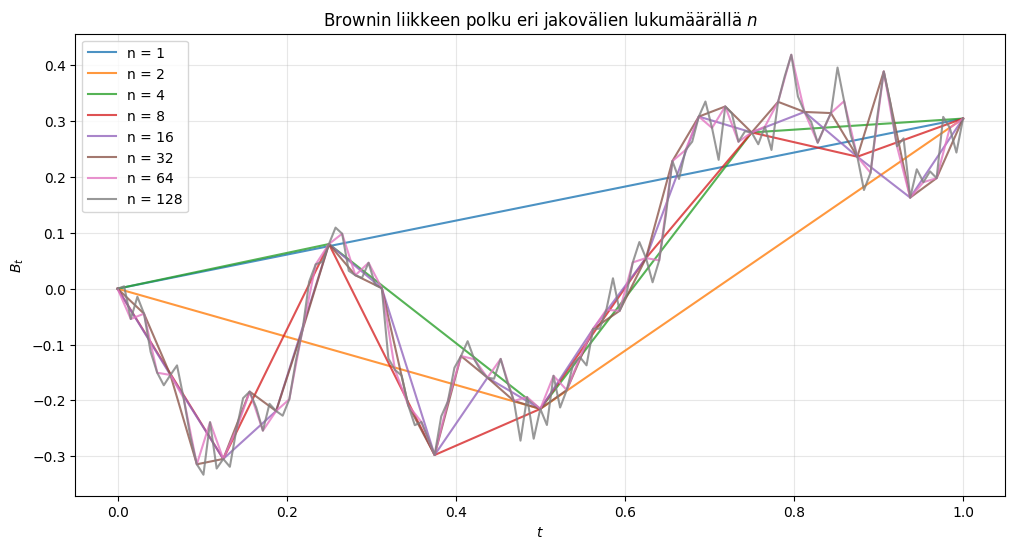

In [ ]:
n_max = max(paths.keys())
t_fine = np.linspace(0, 1, n_max + 1)
plt.figure(figsize=(12, 6))
for i in range(len(n_vals)):
    t = np.linspace(0, 1, n_vals[i] + 1)
    B_interp = np.interp(t_fine, t, paths[n_vals[i]])
    
    plt.plot(
        t_fine,
        B_interp,
        label=f"n = {n_vals[i]}",
        alpha=0.8
    )

plt.xlabel("$t$")
plt.ylabel("$B_t$")
plt.title("Brownin liikkeen polku eri jakovälien lukumäärällä $n$")
plt.legend()
plt.grid(True, alpha=0.3)
plt.show()


In [19]:
# Signatuuriesimerkki yhdelle Brownin liikkeen realisaatiolle
SEED = 202612312412
J = 1000
M = 2
t = np.linspace(0, 1, J)
dt = t[1] - t[0]
rng = np.random.default_rng(SEED)
Z_1 = rng.normal(0, 1, J - 1)
Bpath = np.zeros(J)
Bpath[1:] = np.cumsum(np.sqrt(dt) * Z_1)
stream = np.column_stack((t, Bpath))
Bsig = iisignature.sig(stream, M)
print(Bsig)

[ 1.00000000e+00  2.19402897e-02  5.00000000e-01 -4.74240903e-04
  2.24145306e-02  2.40688156e-04]


In [17]:
Bsig.shape

(999, 6)

No artists with labels found to put in legend.  Note that artists whose label start with an underscore are ignored when legend() is called with no argument.


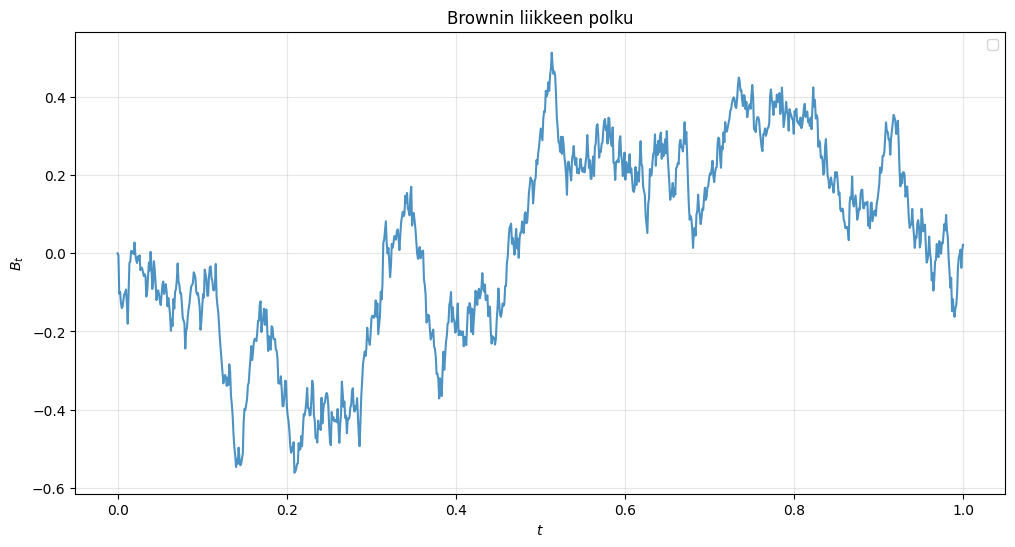

In [6]:
plt.figure(figsize=(12, 6))
plt.plot(
    t,
    Bpath,
    alpha=0.8
)

plt.xlabel("$t$")
plt.ylabel("$B_t$")
plt.title("Brownin liikkeen polku")
plt.legend()
plt.grid(True, alpha=0.3)
plt.show()

In [ ]:
# Polkujen simulointi
SEED = 202612312412
J = 250
M = 10
rho = [-1, -0.25, 0, 0.5, 0.75, 1]
Paths = {}
t = np.linspace(0, 1, J)
dt = t[1] - t[0]
rng = np.random.default_rng(SEED)
Z_1 = rng.normal(0, 1, J - 1)
Z_2 = rng.normal(0, 1, J - 1)

sig_size = iisignature.siglength(2, M) + 1

# Volatiliteettiparametrit
sigma = rng.uniform(0, 0.05, sig_size)

# Simuloidaan Brownin liikkeen polut
Bpaths = np.zeros((2, J))
Bpaths[0, 1:] = np.cumsum(np.sqrt(dt) * Z_1)
Bpaths[1, 1:] = np.cumsum(np.sqrt(dt) * Z_2)

# Lasketaan signatuurit
Bsignatures = np.zeros((2, J, sig_size))
Bsignatures[:, :, 0] = 1.0 

for n in range(2):
  stream = np.column_stack((t, Bpaths[n]))
  Bsignatures[n, 1:, 1:] = iisignature.sig(stream, M, 2)

for r in rho:
  path = np.zeros(J)
  path[0] = 1
  for j in range(J - 1):
    sig_j = Bsignatures[0, j]
    sig_dot_sigma = np.dot(sig_j, sigma)
    dW = r * Z_1[j] + np.sqrt(1 - r**2) * Z_2[j]
    path[j + 1] = path[j] * (1 + sig_dot_sigma * dW)

  Paths[r] = path

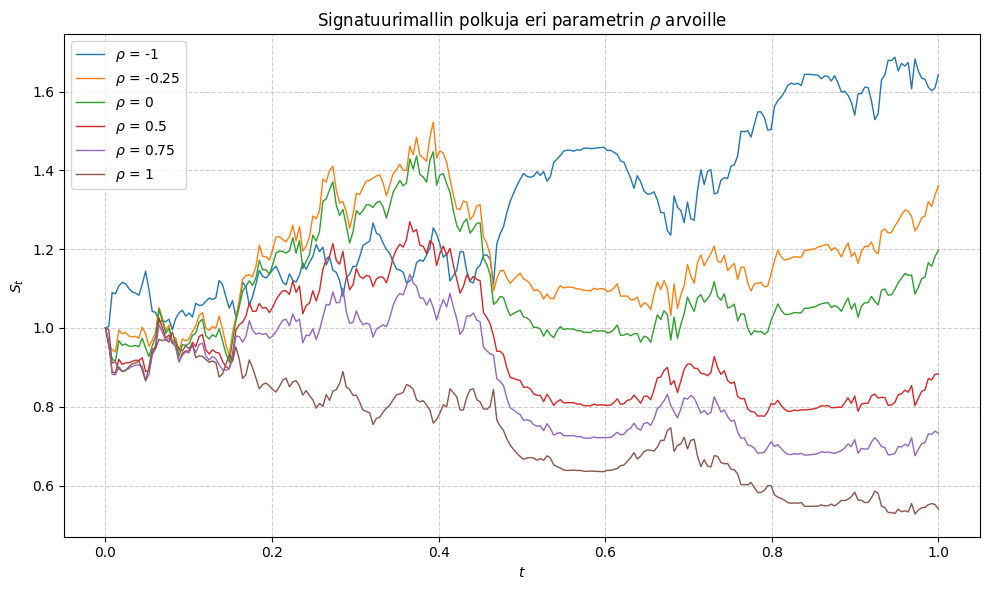

In [10]:
plt.figure(figsize=(10, 6))
for r in rho:
  plt.plot(t, Paths[r], label=f"$\\rho$ = {r}", linewidth=1)

plt.title("Signatuurimallin polkuja eri parametrin $\\rho$ arvoille")
plt.xlabel("$t$")
plt.ylabel("$S_t$")
plt.legend()
plt.grid(True, linestyle="--", alpha=0.6)
plt.tight_layout()
plt.show()

In [2]:
#OU-esimerkki
SEED = 410391249323

J = 1000
N = 1000
M = [1,2,5]
beta1 = 0.05
beta2 = 0.05

ApproxOUPaths = {}

# Simuloidaan N kappaletta Brownin liikkeen polkuja
print(f"Luodaan {N} simulaatiota Brownin liikkeen poluista")
print(f"Status: Työn alla...")
t = np.linspace(0, 1, J)
dt = t[1] - t[0]
rng = np.random.default_rng(SEED)
Z = rng.normal(0, 1, (N, J-1))

Bpaths = np.zeros((N, J))
Bpaths[:, 1:] = np.cumsum(np.sqrt(dt) * Z, axis=1)
print(f"Status: Valmis!")

# Generoidaan OU-prosessit Brownin liikkeistä
print(f"Generoidaan OU-prosessit Brownin liikkeistä")
theta, mu, sigma = 1.0, 0.25, 1.25
OUpaths = np.zeros((N, J))
for j in range(J-1):
  OUpaths[:, j+1] = OUpaths[:, j] + theta * (mu - OUpaths[:, j]) * dt + sigma * np.sqrt(dt) * Z[:, j]

# Generoidaan approksimoitava OU-prosessi
print(f"Generoidaan approksimoitava kohdeprosessi")
TargetZ = rng.normal(0, 1, J-1)
TargetOUpath = np.zeros(J)
for j in range(J-1):
  TargetOUpath[j+1] = TargetOUpath[j] + theta * (mu - TargetOUpath[j]) * dt + sigma * np.sqrt(dt) * TargetZ[j]

# Minimoitava regressiolauseke ja sen gradientti
def objective_and_grad(f, signatures, targetpaths, beta1, beta2):
  predictions = np.tensordot(signatures, f, axes=([2], [0]))
  mse = np.mean((targetpaths - predictions) ** 2)
  penalty = beta1 * np.sum(np.abs(f)) + beta2 * np.sum(f**2)
  obj_value = mse + penalty

  # Lasketaan gradientti
  residuals = predictions - targetpaths
  grad_mse = 2 * np.mean(signatures * residuals[:, :, np.newaxis], axis=(0, 1))
  grad_l1 = beta1 * np.sign(f)
  grad_l2 = 2 * beta2 * f
  grad_f = grad_mse + grad_l1 + grad_l2

  return obj_value, grad_f

# Lasketaan regressioparametrit eri katkaisuasteille
for m in M:
  # Lasketaan Brownin liikkeiden signatuurit jokaiselle aika-askeleelle
  print(f"Aloitetaan signatuurien laskeminen katkaisuasteella {m}")
  sig_size = iisignature.siglength(2, m) + 1

  Bsignatures = np.zeros((N, J, sig_size))
  Bsignatures[:, :, 0] = 1.0

  for n in range(N):
    stream = np.column_stack((t, Bpaths[n]))
    Bsignatures[n, 1:, 1:] = iisignature.sig(stream, m, 2)

  # Etsitään argmin f
  print(f"Etsitään regressioparametrit")
  x0 = np.random.uniform(-1,1,sig_size)
  OptimResult = minimize(objective_and_grad, x0=x0, args=(Bsignatures, OUpaths, beta1, beta2), method="L-BFGS-B", jac=True)
  fstar = OptimResult.x
  print(f"Regressioparametrit löydetty!")

  TargetStream = np.column_stack((t, TargetOUpath))
  Targetsignatures = np.zeros((J, sig_size))
  Targetsignatures[:, 0] = 1.0
  Targetsignatures[1:, 1:] = iisignature.sig(TargetStream, m, 2)

  # Lasketaan regressiopolku matriisi-vektori-tulolla
  print(f"Lasketaan regressiopolku")
  ApproxPath = Targetsignatures @ fstar
  ApproxOUPaths[m] = ApproxPath
  print(f"Approksimointiprosessi valmis!")

Luodaan 1000 simulaatiota Brownin liikkeen poluista
Status: Työn alla...
Status: Valmis!
Generoidaan OU-prosessit Brownin liikkeistä
Generoidaan approksimoitava kohdeprosessi
Aloitetaan signatuurien laskeminen katkaisuasteella 1
Etsitään regressioparametrit
Regressioparametrit löydetty!
Lasketaan regressiopolku
Approksimointiprosessi valmis!
Aloitetaan signatuurien laskeminen katkaisuasteella 2
Etsitään regressioparametrit
Regressioparametrit löydetty!
Lasketaan regressiopolku
Approksimointiprosessi valmis!
Aloitetaan signatuurien laskeminen katkaisuasteella 5
Etsitään regressioparametrit
Regressioparametrit löydetty!
Lasketaan regressiopolku
Approksimointiprosessi valmis!


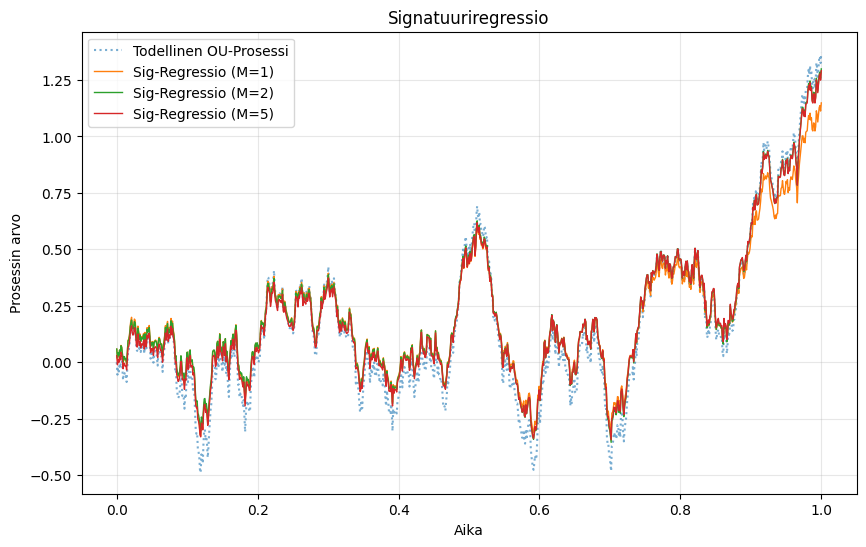

In [3]:
# Luodaan kuvaaja
plt.figure(figsize=(10, 6))
plt.plot(t, TargetOUpath, linestyle="dotted", label="Todellinen OU-Prosessi", alpha=0.6)
for m in M:
  plt.plot(t, ApproxOUPaths[m], label=f"Sig-Regressio (M={m})", linewidth=1)
plt.title(f"Signatuuriregressio")
plt.xlabel("Aika")
plt.ylabel("Prosessin arvo")
plt.legend()
plt.grid(True, alpha=0.3)
plt.show()

In [4]:
print("--- Mean Squared Error (MSE) for each M ---")
for m in M:
  mse = np.mean((TargetOUpath - ApproxOUPaths[m]) ** 2)
  print(f"M={m}: MSE = {mse:.5e}")

--- Mean Squared Error (MSE) for each M ---
M=1: MSE = 6.34401e-03
M=2: MSE = 3.88470e-03
M=5: MSE = 3.26196e-03


In [10]:
#GBM-esimerkki
SEED = 8598433798

J = 1000
N = 1000
M = [1,2,5]
beta1 = 0.05
beta2 = 0.05

ApproxGBMPaths = {}

rng = np.random.default_rng(SEED)

# Simuloidaan N kappaletta Brownin liikkeen polkuja
print(f"Luodaan {N} simulaatiota Brownin liikkeen poluista")
print(f"Status: Työn alla...")
t = np.linspace(0, 1, J)
dt = t[1] - t[0]
rng = np.random.default_rng(SEED)
Z = rng.normal(0, 1, (N, J-1))

Bpaths = np.zeros((N, J))
Bpaths[:, 1:] = np.cumsum(np.sqrt(dt) * Z, axis=1)
print(f"Status: Valmis!")

# Generoidaan GBM-prosessit Brownin liikkeistä
print(f"Generoidaan GBM-prosessit Brownin liikkeistä")
mu, sigma = 0.15, 0.25
GBMpaths = np.zeros((N, J))
GBMpaths[:, 0] = 1.0
for j in range(J-1):
  GBMpaths[:, j+1] = GBMpaths[:, j] * (1 + mu * dt + sigma * np.sqrt(dt) * Z[:, j])

# Generoidaan approksimoitava GBM-prosessi
print(f"Generoidaan approksimoitava kohdeprosessi")
TargetZ = rng.normal(0, 1, J-1)
TargetGBMpath = np.zeros(J)
TargetGBMpath[0] = 1.0
for j in range(J-1):
  TargetGBMpath[j+1] = TargetGBMpath[j] * (1 + mu * dt + sigma * np.sqrt(dt) * TargetZ[j])

# Minimoitava regressiolauseke ja sen gradientti
def regressfunc_w_grad(f, signatures, targetpaths, beta1, beta2):
  predictions = np.tensordot(signatures, f, axes=([2], [0]))
  mse = np.mean((targetpaths - predictions) ** 2)
  penalty = beta1 * np.sum(np.abs(f)) + beta2 * np.sum(f**2)
  obj_value = mse + penalty

  # Lasketaan gradientti
  residuals = predictions - targetpaths
  grad_mse = 2 * np.mean(signatures * residuals[:, :, np.newaxis], axis=(0, 1))
  grad_l1 = beta1 * np.sign(f)
  grad_l2 = 2 * beta2 * f
  grad_f = grad_mse + grad_l1 + grad_l2

  return obj_value, grad_f

# Lasketaan regressioparametrit eri katkaisuasteille
for m in M:
  # Lasketaan Brownin liikkeiden signatuurit jokaiselle aika-askeleelle
  print(f"Lasketaan signatuurit katkaisuasteella {m}")
  sig_size = iisignature.siglength(2, m) + 1

  Bsignatures = np.zeros((N, J, sig_size))
  Bsignatures[:, :, 0] = 1.0

  for n in range(N):
    stream = np.column_stack((t, Bpaths[n]))
    Bsignatures[n, 1:, 1:] = iisignature.sig(stream, m, 2)

  # Etsitään argmin f
  print(f"Etsitään regressioparametrit")
  x0 = np.random.uniform(-1,1,sig_size)
  OptimResult = minimize(regressfunc_w_grad, x0=x0, args=(Bsignatures, Bpaths, beta1, beta2), method="L-BFGS-B", jac=True)
  fstar_gbm = OptimResult.x
  print(f"Regressioparametrit löydetty!")

  TargetStream = np.column_stack((t, TargetGBMpath))
  Targetsignatures = np.zeros((J, sig_size))
  Targetsignatures[:, 0] = 1.0
  Targetsignatures[1:, 1:] = iisignature.sig(TargetStream, m, 2)

  # Lasketaan regressiopolku matriisi-vektori-tulolla
  print(f"Lasketaan regressiopolku")
  ApproxPath = Targetsignatures @ fstar_gbm
  ApproxPath[:] += 1
  ApproxGBMPaths[m] = ApproxPath
  print(f"Approksimointiprosessi valmis!")

Luodaan 1000 simulaatiota Brownin liikkeen poluista
Status: Työn alla...
Status: Valmis!
Generoidaan GBM-prosessit Brownin liikkeistä
Generoidaan approksimoitava kohdeprosessi
Lasketaan signatuurit katkaisuasteella 1
Etsitään regressioparametrit
Regressioparametrit löydetty!
Lasketaan regressiopolku
Approksimointiprosessi valmis!
Lasketaan signatuurit katkaisuasteella 2
Etsitään regressioparametrit
Regressioparametrit löydetty!
Lasketaan regressiopolku
Approksimointiprosessi valmis!
Lasketaan signatuurit katkaisuasteella 5
Etsitään regressioparametrit
Regressioparametrit löydetty!
Lasketaan regressiopolku
Approksimointiprosessi valmis!


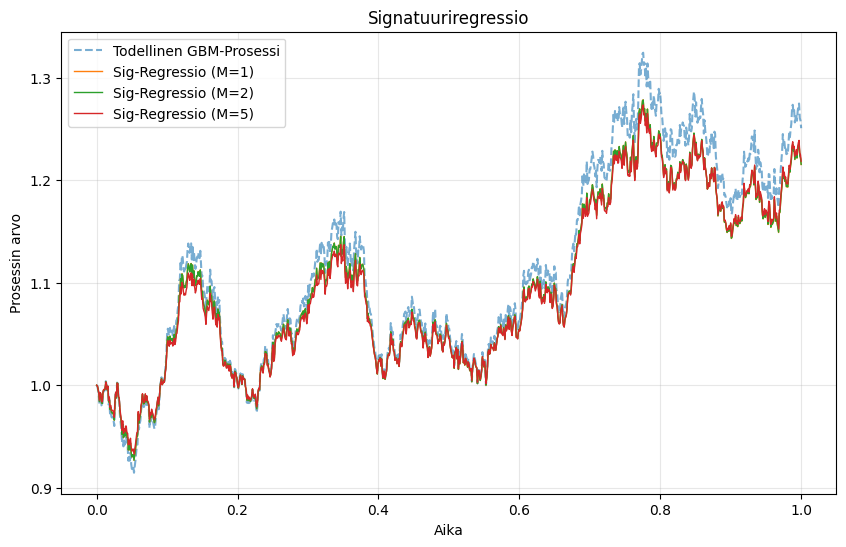

In [11]:
# Luodaan kuvaaja
plt.figure(figsize=(10, 6))
plt.plot(t, TargetGBMpath, linestyle="dashed", label="Todellinen GBM-Prosessi", alpha=0.6)
for m in M:
  plt.plot(t, ApproxGBMPaths[m], label=f"Sig-Regressio (M={m})", linewidth=1)
plt.title(f"Signatuuriregressio")
plt.xlabel("Aika")
plt.ylabel("Prosessin arvo")
plt.legend()
plt.grid(True, alpha=0.3)
plt.show()

In [7]:
print("--- Mean Squared Error (MSE) for each M ---")
for m in M:
  mse = np.mean((TargetGBMpath - ApproxGBMPaths[m]) ** 2)
  print(f"M={m}: MSE = {mse:.5e}")

--- Mean Squared Error (MSE) for each M ---
M=1: MSE = 4.32180e-04
M=2: MSE = 4.42533e-04
M=5: MSE = 4.99408e-04


In [ ]:
#GBM-esimerkin jatkoa out-of-sample
SEED = 8598433798

J = 1000
N = 1000
M = [1,2,5]
beta1 = 0.05
beta2 = 0.05

fstar_gbm_dict = {}

rng = np.random.default_rng(SEED)

# Simuloidaan N kappaletta Brownin liikkeen polkuja
print(f"Luodaan {N} simulaatiota Brownin liikkeen poluista")
print(f"Status: Työn alla...")
t = np.linspace(0, 1, J)
dt = t[1] - t[0]
rng = np.random.default_rng(SEED)
Z = rng.normal(0, 1, (N, J-1))

Bpaths = np.zeros((N, J))
Bpaths[:, 1:] = np.cumsum(np.sqrt(dt) * Z, axis=1)
print(f"Status: Valmis!")

# Generoidaan GBM-prosessit Brownin liikkeistä
print(f"Generoidaan GBM-prosessit Brownin liikkeistä")
mu, sigma = 0.15, 0.25
GBMpaths = np.zeros((N, J))
GBMpaths[:, 0] = 1.0
for j in range(J-1):
  GBMpaths[:, j+1] = GBMpaths[:, j] * (1 + mu * dt + sigma * np.sqrt(dt) * Z[:, j])

# Generoidaan approksimoitava GBM-prosessi
print(f"Generoidaan approksimoitava kohdeprosessi")
TargetZ = rng.normal(0, 1, J-1)
TargetGBMpath = np.zeros(J)
TargetGBMpath[0] = 1.0
for j in range(J-1):
  TargetGBMpath[j+1] = TargetGBMpath[j] * (1 + mu * dt + sigma * np.sqrt(dt) * TargetZ[j])

# Minimoitava regressiolauseke ja sen gradientti
def regressfunc_w_grad(f, signatures, targetpaths, beta1, beta2):
  predictions = np.tensordot(signatures, f, axes=([2], [0]))
  mse = np.mean((targetpaths - predictions) ** 2)
  penalty = beta1 * np.sum(np.abs(f)) + beta2 * np.sum(f**2)
  obj_value = mse + penalty

  # Lasketaan gradientti
  residuals = predictions - targetpaths
  grad_mse = 2 * np.mean(signatures * residuals[:, :, np.newaxis], axis=(0, 1))
  grad_l1 = beta1 * np.sign(f)
  grad_l2 = 2 * beta2 * f
  grad_f = grad_mse + grad_l1 + grad_l2

  return obj_value, grad_f

# Lasketaan regressioparametrit eri katkaisuasteille
for m in M:
  # Lasketaan Brownin liikkeiden signatuurit jokaiselle aika-askeleelle
  print(f"Lasketaan signatuurit katkaisuasteella {m}")
  sig_size = iisignature.siglength(2, m) + 1

  Bsignatures = np.zeros((N, J, sig_size))
  Bsignatures[:, :, 0] = 1.0

  for n in range(N):
    stream = np.column_stack((t, Bpaths[n]))
    Bsignatures[n, 1:, 1:] = iisignature.sig(stream, m, 2)

  # Etsitään argmin f
  print(f"Etsitään regressioparametrit")
  x0 = np.random.uniform(-1,1,sig_size)
  OptimResult = minimize(regressfunc_w_grad, x0=x0, args=(Bsignatures, Bpaths, beta1, beta2), method="L-BFGS-B", jac=True)
  fstar_gbm = OptimResult.x
  fstar_gbm_dict[m] = fstar_gbm
  print(f"Regressioparametrit löydetty!")

Luodaan 1000 simulaatiota Brownin liikkeen poluista
Status: Työn alla...
Status: Valmis!
Generoidaan GBM-prosessit Brownin liikkeistä
Generoidaan approksimoitava kohdeprosessi
Lasketaan signatuurit katkaisuasteella 1
Etsitään regressioparametrit
Regressioparametrit löydetty!
Lasketaan signatuurit katkaisuasteella 2
Etsitään regressioparametrit
Regressioparametrit löydetty!
Lasketaan signatuurit katkaisuasteella 5
Etsitään regressioparametrit
Regressioparametrit löydetty!


In [90]:
extension_length = 4
J_ext = extension_length*J
t_extension = np.linspace(0, extension_length+1, J+J_ext)
dt = t[1] - t[0]

SEED = 4112026314

rng = np.random.default_rng(SEED)

TargetZ = rng.normal(0, 1, J_ext-1)

ApproxGBMExtensions = {}

TargetGBMextension = np.zeros(J_ext)
TargetGBMextension[0] = TargetGBMpath[-1]
for j in range(J_ext-1):
  TargetGBMextension[j+1] = TargetGBMextension[j] * (1 + mu * dt + sigma * np.sqrt(dt) * TargetZ[j])

full_gbm_path = np.concatenate((TargetGBMpath, TargetGBMextension))

for m in M:
  sig_size = iisignature.siglength(2, m) + 1
  TargetStream = np.column_stack((t_extension, full_gbm_path))
  Targetsignatures = np.zeros((len(full_gbm_path), sig_size))
  Targetsignatures[:, 0] = 1.0
  Targetsignatures[1:, 1:] = iisignature.sig(TargetStream, m, 2)
  # Lasketaan regressiopolku matriisi-vektori-tulolla
  print(f"Lasketaan regressiopolku")
  ApproxPath = Targetsignatures @ fstar_gbm_dict[m]
  ApproxPath[:] += 1
  ApproxGBMExtensions[m] = ApproxPath
  print(f"Approksimointiprosessi valmis!")

Lasketaan regressiopolku
Approksimointiprosessi valmis!
Lasketaan regressiopolku
Approksimointiprosessi valmis!
Lasketaan regressiopolku
Approksimointiprosessi valmis!


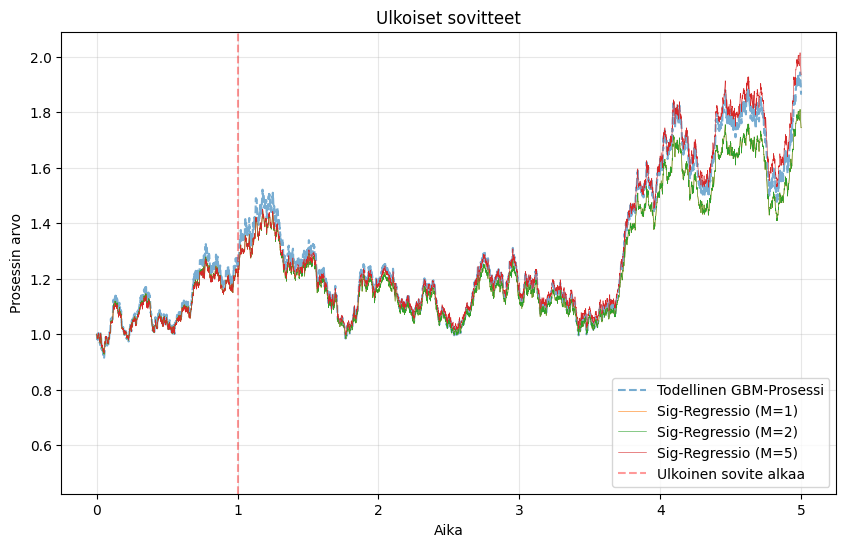

In [95]:
# Luodaan kuvaaja
plt.figure(figsize=(10, 6))
plt.plot(t_extension, full_gbm_path, linestyle="dashed", label="Todellinen GBM-Prosessi", alpha=0.6)
for m in M:
  plt.plot(t_extension, ApproxGBMExtensions[m], label=f"Sig-Regressio (M={m})", linewidth=0.4)
plt.axline((1,0.5),(1,1), linestyle="dashed", label="Ulkoinen sovite alkaa", alpha=0.4, color="r")
plt.title(f"Ulkoiset sovitteet")
plt.xlabel("Aika")
plt.ylabel("Prosessin arvo")
plt.legend()
plt.grid(True, alpha=0.3)
plt.show()

In [98]:
print("--- Mean Squared Error (MSE) for each M ---")
for index in range(2*J,2*J+extension_length*J,J):
  print(index)
  for m in M:
    mse = np.mean((full_gbm_path[index-100:index] - ApproxGBMExtensions[m][index-100:index]) ** 2)
    print(f"M={m}: MSE = {mse:.5e}")

--- Mean Squared Error (MSE) for each M ---
2000
M=1: MSE = 7.71050e-04
M=2: MSE = 7.72224e-04
M=5: MSE = 8.23593e-05
3000
M=1: MSE = 1.03595e-03
M=2: MSE = 1.03528e-03
M=5: MSE = 2.57077e-05
4000
M=1: MSE = 5.90151e-03
M=2: MSE = 5.86173e-03
M=5: MSE = 1.12622e-04
5000
M=1: MSE = 1.30583e-02
M=2: MSE = 1.29452e-02
M=5: MSE = 4.30818e-03


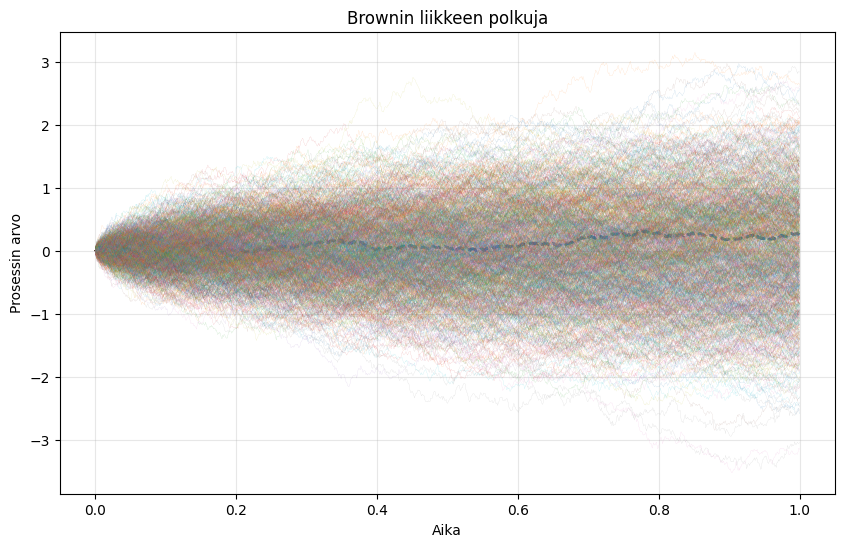

In [9]:
plt.figure(figsize=(10, 6))
plt.plot(t, TargetGBMpath - 1, linestyle="dashed", label="Todellinen GBM-Prosessi", linewidth = 2)
for path in Bpaths:
  plt.plot(t, path, linewidth = 0.1, alpha = 0.5)
plt.title(f"Brownin liikkeen polkuja")
plt.xlabel("Aika")
plt.ylabel("Prosessin arvo")
plt.grid(True, alpha=0.3)
plt.show()
